---
# **Taller 04 - K-Means Clustering**
---

#



## **2. Importación de librerías**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score
from sklearn.neighbors import LocalOutlierFactor


## **3. Generación de los datos sintéticos**

Creamos 6 grupos gaussianos con la misma cantidad de puntos pero distinta
desviación estándar (distinta densidad)

In [2]:
np.random.seed(300)

nclusters_creados = 6
ndatos = 150

# Centros de los seis grupos.
# Los grupos 5 y 6 están cercanos para generar solapamiento parcial.
centros = np.array([
    [-6.0, -6.0],
    [-2.0, -2.0],
    [ 2.0,  2.0],
    [ 6.0,  6.0],
    [-2.0,  6.0],
    [ 0.5,  6.0]
])

# Diferentes desviaciones estándar = diferentes densidades.
desviaciones = [0.35, 0.60, 0.90, 1.20, 0.75, 0.75]

x1 = []
x2 = []
y = []

for i in range(nclusters_creados):
    grupo = np.random.normal(
        loc=centros[i],
        scale=desviaciones[i],
        size=(ndatos, 2)
    )

    # Garantizar que todos los puntos estén entre -10 y 10.
    grupo = np.clip(grupo, -10, 10)

    x1.extend(grupo[:, 0])
    x2.extend(grupo[:, 1])
    y.extend([i] * ndatos)

x1 = np.array(x1)
x2 = np.array(x2)
y = np.array(y)

X = np.column_stack((x1, x2))

print("Número de clusters creados:", nclusters_creados)
print("Número de datos por cluster:", ndatos)
print("Número total de datos:", len(X))
print("Mínimos:", X.min(axis=0))
print("Máximos:", X.max(axis=0))


Número de clusters creados: 6
Número de datos por cluster: 150
Número total de datos: 900
Mínimos: [-6.58617934 -6.84508771]
Máximos: [8.90431414 9.42784425]


## **4. Visualización de los grupos generados**

Se ven los 6 grupos. Los grupos 5 y 6 aparecen mezclados entre sí

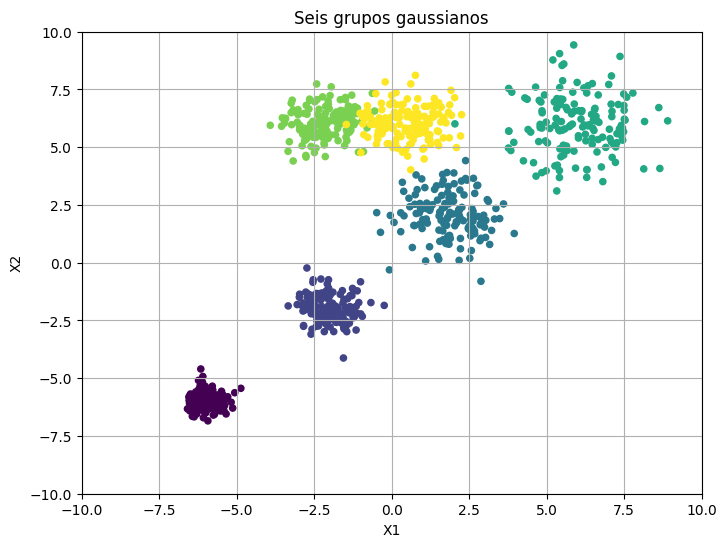

In [3]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="viridis",
    s=20
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Seis grupos gaussianos")
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.grid()
plt.show()


## **5. Agregar outliers**




Agregamos 30 puntos al azar (uniformes entre -10 y 10) que no pertenecen a ningún grupo

In [4]:
np.random.seed(42)

n_outliers = 30

X_outliers = np.random.uniform(
    low=-10,
    high=10,
    size=(n_outliers, 2)
)

X_all = np.r_[X, X_outliers]

# -1 representa los outliers en las etiquetas conocidas.
y_all = np.r_[y, np.full(n_outliers, -1)]

print("Número de outliers agregados:", n_outliers)
print("Total de datos con outliers:", len(X_all))


Número de outliers agregados: 30
Total de datos con outliers: 930


## **6. Visualización de los datos con outliers**

Los outliers se ven dispersos por todo el espacio, sin formar ningún grupo

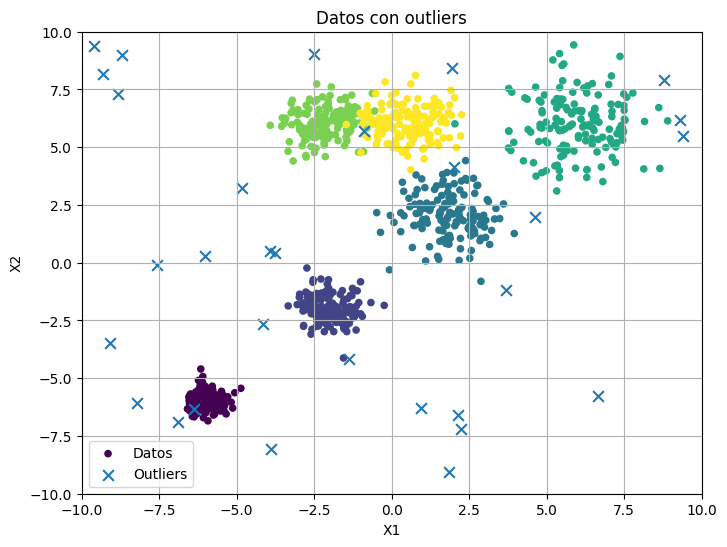

In [5]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y,
    cmap="viridis",
    s=20,
    label="Datos"
)

plt.scatter(
    X_outliers[:, 0],
    X_outliers[:, 1],
    marker="x",
    s=60,
    label="Outliers"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Datos con outliers")
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.legend()
plt.grid()
plt.show()


## **7. Remoción de outliers con Local Outlier Factor (LOF)**



Detecta los puntos que están muy aislados de sus vecinos y los marca como outliers

In [6]:
clf = LocalOutlierFactor(
    n_neighbors=50,
    contamination=n_outliers / len(X_all)
)

y_pred_outliers = clf.fit_predict(X_all)

# Los puntos con predicción 1 se consideran normales.
X_limpio = X_all[y_pred_outliers == 1]

# Conservamos el Ground Truth correspondiente a los puntos que quedaron.
y_limpio = y_all[y_pred_outliers == 1]

print("Datos originales con outliers:", len(X_all))
print("Datos después de remover outliers:", len(X_limpio))
print("Outliers detectados:", np.sum(y_pred_outliers == -1))


Datos originales con outliers: 930
Datos después de remover outliers: 900
Outliers detectados: 30


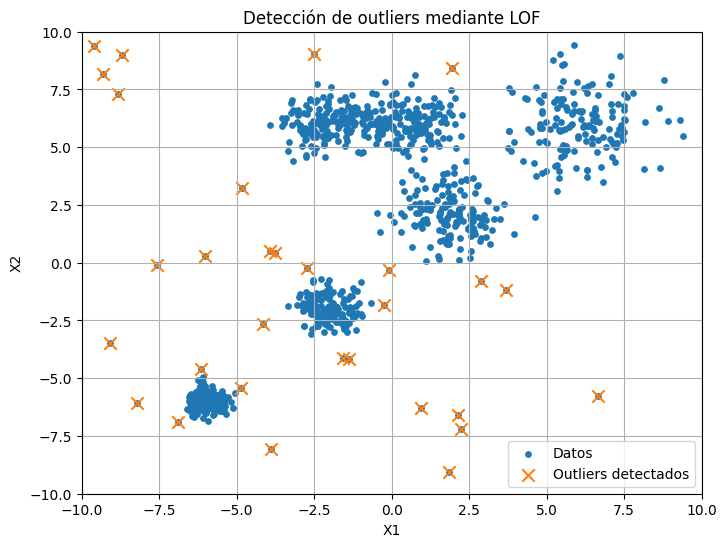

In [7]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_all[:, 0],
    X_all[:, 1],
    s=15,
    label="Datos"
)

outliers_detectados = y_pred_outliers == -1

plt.scatter(
    X_all[outliers_detectados, 0],
    X_all[outliers_detectados, 1],
    s=80,
    marker="x",
    label="Outliers detectados"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Detección de outliers mediante LOF")
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.legend()
plt.grid()
plt.show()


---
## **8. Aplicación de K-Means**



Probamos K-means con K de 2 a 12 y guardamos la inercia, el Silhouette, el ARI y el NMI de cada K para compararlos después

In [8]:
K_range = range(2, 13)

inertia = []
silhouette_scores = []
ari_scores = []
nmi_scores = []

modelos = {}
labels_por_k = {}

for k in K_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=0,
        n_init=10
    )

    labels = kmeans.fit_predict(X_limpio)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_limpio, labels))

    # Para Ground Truth se excluyen posibles puntos con etiqueta -1.
    mascara_ground_truth = y_limpio != -1

    ari_scores.append(
        adjusted_rand_score(
            y_limpio[mascara_ground_truth],
            labels[mascara_ground_truth]
        )
    )

    nmi_scores.append(
        normalized_mutual_info_score(
            y_limpio[mascara_ground_truth],
            labels[mascara_ground_truth]
        )
    )

    modelos[k] = kmeans
    labels_por_k[k] = labels

resultados = pd.DataFrame({
    "K": list(K_range),
    "Inercia": inertia,
    "Silhouette": silhouette_scores,
    "ARI": ari_scores,
    "NMI": nmi_scores
})

resultados


,K,Inercia,Silhouette,ARI,NMI
0,2,10483.178222,0.617683,0.272835,0.522988
1,3,6226.986749,0.566216,0.472605,0.709016
2,4,3838.747076,0.596253,0.617806,0.776728
3,5,1609.486927,0.686901,0.814211,0.919640
4,6,1081.573626,0.655635,0.953657,0.955876
5,7,942.054950,0.604140,0.900203,0.926103
6,8,833.437352,0.613084,0.881593,0.909606
7,9,741.489388,0.572379,0.829390,0.884247
8,10,658.628736,0.531564,0.738747,0.849304
9,11,617.788298,0.515404,0.721382,0.841150


## **9. Método del Codo**




La inercia baja rápido al principio y luego se aplana. El punto donde se aplana ("el codo") es una posible pista del mejor K

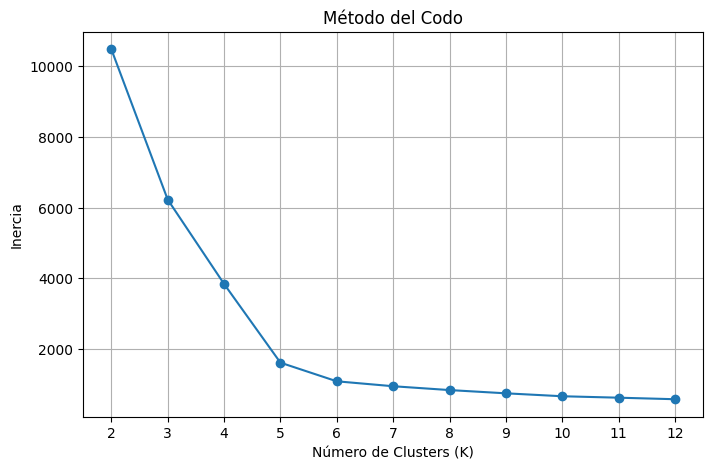

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    inertia,
    marker="o"
)

plt.xlabel("Número de Clusters (K)")
plt.ylabel("Inercia")
plt.title("Método del Codo")
plt.xticks(list(K_range))
plt.grid()
plt.show()


## **10. Método de Silhouette**




El mejor K según Silhouette es 5. Como los grupos 5 y 6 están solapados, Silhouette los ve como uno solo, por eso da un K menor al real

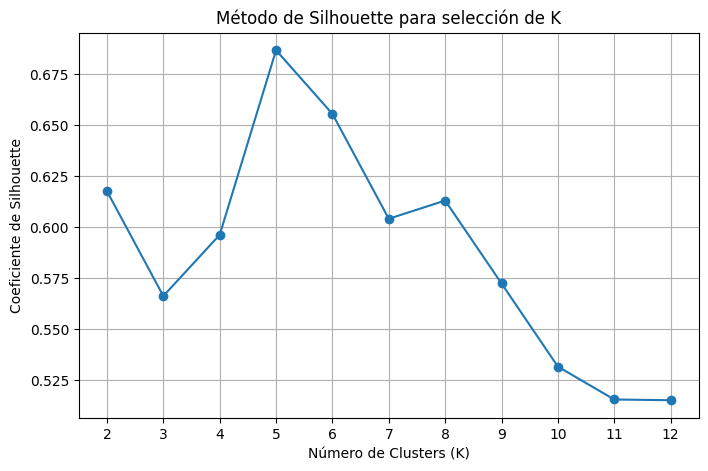

K óptimo según Silhouette: 5
Coeficiente máximo: 0.6869011426215558


In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Número de Clusters (K)")
plt.ylabel("Coeficiente de Silhouette")
plt.title("Método de Silhouette para selección de K")
plt.xticks(list(K_range))
plt.grid()
plt.show()

k_silhouette = list(K_range)[np.argmax(silhouette_scores)]

print("K óptimo según Silhouette:", k_silhouette)
print("Coeficiente máximo:", max(silhouette_scores))


## **11. Evaluación mediante Ground Truth**




ARI y NMI sí conocen las etiquetas reales, y ambos dan K = 6, que es el número real de grupos

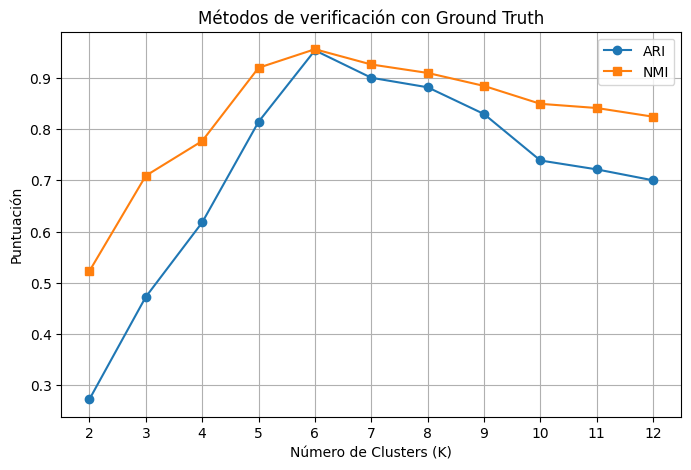

K óptimo según ARI: 6
Mayor ARI: 0.9536565968672156
K óptimo según NMI: 6
Mayor NMI: 0.9558763462001904


In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    K_range,
    ari_scores,
    marker="o",
    label="ARI"
)

plt.plot(
    K_range,
    nmi_scores,
    marker="s",
    label="NMI"
)

plt.xlabel("Número de Clusters (K)")
plt.ylabel("Puntuación")
plt.title("Métodos de verificación con Ground Truth")
plt.xticks(list(K_range))
plt.legend()
plt.grid()
plt.show()

k_ari = list(K_range)[np.argmax(ari_scores)]
k_nmi = list(K_range)[np.argmax(nmi_scores)]

print("K óptimo según ARI:", k_ari)
print("Mayor ARI:", max(ari_scores))
print("K óptimo según NMI:", k_nmi)
print("Mayor NMI:", max(nmi_scores))


## **12. Comparación de los resultados**

El codo y Silhouette sugieren un K menor porque no distinguen bien los grupos solapados. ARI y NMI aciertan en K = 6 porque usan las etiquetas reales

In [12]:
print("K óptimo según Silhouette:", k_silhouette)
print("K óptimo según Ground Truth - ARI:", k_ari)
print("K óptimo según Ground Truth - NMI:", k_nmi)

display(resultados)


K óptimo según Silhouette: 5
K óptimo según Ground Truth - ARI: 6
K óptimo según Ground Truth - NMI: 6


,K,Inercia,Silhouette,ARI,NMI
0,2,10483.178222,0.617683,0.272835,0.522988
1,3,6226.986749,0.566216,0.472605,0.709016
2,4,3838.747076,0.596253,0.617806,0.776728
3,5,1609.486927,0.686901,0.814211,0.919640
4,6,1081.573626,0.655635,0.953657,0.955876
5,7,942.054950,0.604140,0.900203,0.926103
6,8,833.437352,0.613084,0.881593,0.909606
7,9,741.489388,0.572379,0.829390,0.884247
8,10,658.628736,0.531564,0.738747,0.849304
9,11,617.788298,0.515404,0.721382,0.841150


## **13. Visualización del clustering final**




Usamos K = 6 (el valor de ARI) porque sabemos que ese es el número real de grupos, aunque Silhouette y el codo hayan sugerido menos

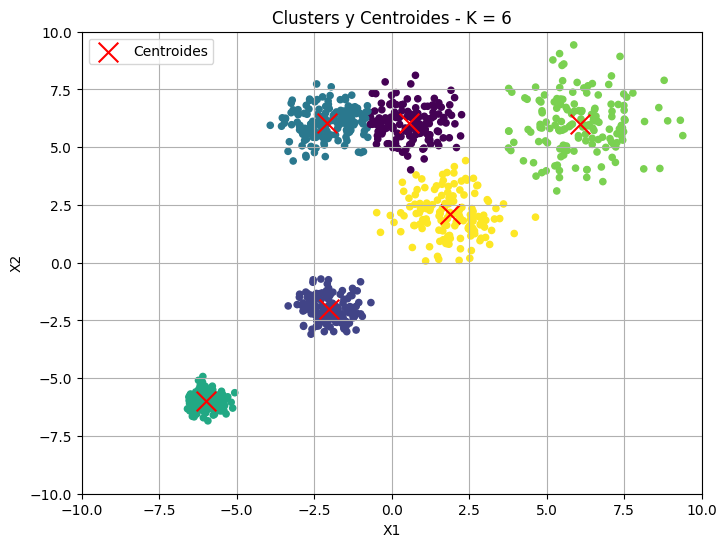

In [13]:
k_final = k_ari

kmeans_final = modelos[k_final]
labels_final = labels_por_k[k_final]
centroids = kmeans_final.cluster_centers_

plt.figure(figsize=(8, 6))

plt.scatter(
    X_limpio[:, 0],
    X_limpio[:, 1],
    c=labels_final,
    cmap="viridis",
    s=20
)

plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="x",
    s=200,
    c="red",
    label="Centroides"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title(f"Clusters y Centroides - K = {k_final}")
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.legend()
plt.grid()
plt.show()
